# 05 · Random Forest (California Housing)

**Input:** `../data/processed/california_housing_clean.csv` · **Target:** `MedHouseVal` (regression, ឯកតា $100,000)

## 1. Goal
ដោះស្រាយបញ្ហារបស់ Decision Tree តែមួយ (**មិនស្ថិតស្ថេរ**, ងាយ overfit) ដោយរួមបញ្ចូល trees ជាច្រើន។ Random Forest ជា models ដំបូងដែល data scientist សាកល្បងលើ tabular data
ព្រោះវាត្រូវការ tuning តិច ហើយជារឿយៗល្អជាង Linear Regression និង KNN។

## Concept
**ឧបមា "សួរទស្សនិកជន":** ក្នុងកម្មវិធីល្បែងឆ្លើយសំណួរ ការសួរទស្សនិកជនទាំងមូលជាធម្មតាល្អជាងការសួរអ្នកជំនាញតែម្នាក់ ព្រោះកំហុសរបស់បុគ្គលម្នាក់ៗលុបបំបាត់គ្នាទៅវិញទៅមក។
Random Forest ធ្វើបែបនេះ:
1. **Bootstrap:** tree នីមួយៗត្រូវបាន train លើគំរូចៃដន្យនៃ training rows (ចាប់យក **ជាមួយការដាក់ត្រឡប់** ទំហំស្មើនឹង train)។ ដូច្នេះ trees មើលឃើញ data ខុសគ្នា។
2. **Random features:** នៅរាល់ split tree អាចពិចារណាបានតែ **សំណុំរងចៃដន្យ** នៃ features (ជាមួយ `max_features`)។
3. **Regression: ទាយ = មធ្យម** នៃការទាយរបស់ trees ទាំងអស់ (Classification ក្នុង Titanic ប្រើការបោះឆ្នោត)។

Tree ជ្រៅនីមួយៗមាន **bias ទាប ប៉ុន្តែ variance ខ្ពស់**។ ដោយសារ trees ធ្វើកំហុស *ខុសៗគ្នា* ការយកមធ្យមបន្ថយ **variance** ខ្លាំង ដោយមិនបន្ថែម bias ច្រើនទេ។

**OOB (out-of-bag):** ដោយសារ tree នីមួយៗមិនឃើញ rows ប្រហែល 37% ដែលមិនត្រូវបានចាប់យក យើងអាចដាក់ពិន្ទុ row នីមួយៗ ដោយ trees ដែល **មិនធ្លាប់ឃើញវា** ប៉ុណ្ណោះ។
នេះផ្តល់ validation score **ឥតគិតថ្លៃ** ពី training set តែប៉ុណ្ណោះ (មិនប៉ះ test set)។

Import libraries។

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

pd.set_option("display.max_columns", None)
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"

def style(ax):
    """Light grid, no top/right spines."""
    ax.grid(color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=9)

def evaluate(model, A, B):
    """Train and test MAE / RMSE / R2 for a fitted model. A = train features, B = test features."""
    out = {}
    for split, Xs, ys in [("train", A, y_train), ("test", B, y_test)]:
        pred = model.predict(Xs)
        out[f"{split} MAE"] = mean_absolute_error(ys, pred)
        out[f"{split} RMSE"] = np.sqrt(mean_squared_error(ys, pred))
        out[f"{split} R2"] = r2_score(ys, pred)
    return out

Load clean data ហើយ split ដូច Lesson 2 (`test_size=0.2`, `random_state=42`)។ ដូច Decision Tree, forest **មិនត្រូវការ scaling** ទេ ហើយ data នេះគ្មាន missing/categorical ដូច្នេះប្រើ `X_train` ដោយផ្ទាល់។
Scaling ធ្វើតែសម្រាប់ Linear Regression និង KNN ក្នុងការប្រៀបធៀបចុងក្រោយ (fit លើ train តែប៉ុណ្ណោះ)។

In [2]:
df = pd.read_csv("../data/processed/california_housing_clean.csv")
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
feature_names = X.columns.tolist()

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # only for Linear Regression and KNN in section 7
X_test_s = scaler.transform(X_test)
X_train.shape, X_test.shape

((15546, 8), (3887, 8))

## 2. Instability of a single tree
Train tree (`max_depth=9`, ជម្រៅល្អបំផុតពី Lesson 4) 5 ដង ដែលនីមួយៗលើ **bootstrap sample** ខុសគ្នា ហើយប្រៀបធៀប test R²។
បន្ទាប់មកយកមធ្យមនៃការទាយរបស់ trees ទាំង 5។

In [3]:
rng = np.random.RandomState(0)
rows, preds = [], []
for i in range(5):
    idx = rng.choice(len(X_train), size=len(X_train), replace=True)   # sample WITH replacement
    t = DecisionTreeRegressor(max_depth=9, random_state=42).fit(X_train.iloc[idx], y_train.iloc[idx])
    preds.append(t.predict(X_test))
    rows.append({"tree": f"tree {i + 1}", "test R2": r2_score(y_test, preds[-1]),
                 "test RMSE": np.sqrt(mean_squared_error(y_test, preds[-1]))})
avg = np.mean(preds, axis=0)
rows.append({"tree": "average of 5 trees", "test R2": r2_score(y_test, avg), "test RMSE": np.sqrt(mean_squared_error(y_test, avg))})
pd.DataFrame(rows).set_index("tree").round(4)

,test R2,test RMSE
tree,,
tree 1,0.6356,0.5908
tree 2,0.6142,0.6079
tree 3,0.6476,0.5810
tree 4,0.6350,0.5913
tree 5,0.6027,0.6169
average of 5 trees,0.7232,0.5149


**អានលទ្ធផល:** Trees ទាំង 5 មានរចនាសម្ព័ន្ធដូចគ្នា (`max_depth=9`) តែ test R² ខុសគ្នាពី **0.603 ដល់ 0.648** (RMSE 0.581–0.617) ដោយសារតែ bootstrap sample ខុសគ្នា។ នេះជាភាពមិនស្ថិតស្ថេរ (**variance ខ្ពស់**)។
(ពួកវាអន់ជាង tree ធម្មតា depth 9 ក្នុង Lesson 4 ដែលមាន R² 0.671 ព្រោះ bootstrap sample នីមួយៗមើលឃើញតែប្រហែល 63% នៃ rows ខុសគ្នា។)

**ការយកមធ្យមនៃ trees ទាំង 5** ផ្តល់ R² **0.723** ល្អជាង tree នីមួយៗ (និងល្អជាង tree តែមួយល្អបំផុត 0.671 ផង) តែដោយគ្រាន់តែយកមធ្យម។ នេះជាគំនិតរបស់ Random Forest: កំហុសរបស់ trees ខុសគ្នា ដូច្នេះវាលុបបំបាត់គ្នា។

## 3. Random Forest
ព្រៃដែលមាន 300 trees ជ្រៅ (គ្មានដែនកំណត់ `max_depth`)។ `oob_score=True` គណនា OOB R²។ `n_jobs=-1` ប្រើ CPU cores ទាំងអស់។

ចំណាំ: សម្រាប់ **regression** តម្លៃលំនាំដើមរបស់ `max_features` គឺ `1.0` (ប្រើ features ទាំងអស់ គ្រប់ split) ដែលមានន័យថា randomness មកតែពី bootstrap ប៉ុណ្ណោះ។
(Classification ក្នុង Titanic ប្រើ `"sqrt"`។) យើងនឹង tune `max_features` នៅ Step 5។

In [4]:
forest = RandomForestRegressor(n_estimators=300, oob_score=True, random_state=42, n_jobs=-1).fit(X_train, y_train)
tree_9 = DecisionTreeRegressor(max_depth=9, random_state=42).fit(X_train, y_train)
pd.DataFrame({"Tree (max_depth=9)": evaluate(tree_9, X_train, X_test),
              "Random Forest (300 trees)": evaluate(forest, X_train, X_test)}).T.round(3).assign(OOB_R2=[np.nan, round(forest.oob_score_, 3)])

,train MAE,train RMSE,train R2,test MAE,test RMSE,test R2,OOB_R2
Tree (max_depth=9),0.324,0.462,0.774,0.385,0.561,0.671,NaN
Random Forest (300 trees),0.112,0.167,0.970,0.298,0.446,0.792,0.783


**អានលទ្ធផល:** Forest ឈ្នះ tree តែមួយយ៉ាងច្បាស់: test R² **0.792** ទល់ 0.671, MAE **0.298** ទល់ 0.385 ($29,800 ទល់ $38,500), RMSE 0.446 ទល់ 0.561។
- **OOB R² = 0.783** ជិតខ្លាំងនឹង test R² (0.792)។ OOB ត្រូវបានគណនាពី training set តែប៉ុណ្ណោះ ប៉ុន្តែបានទស្សន៍ទាយ test score យ៉ាងល្អ។
- **Train R² 0.970 ខ្ពស់ជាង test 0.792 ច្រើន**: forest ក៏ fit ទៅ training data យ៉ាងជិតដែរ ប៉ុន្តែដោយសារកំហុសរបស់ trees ត្រូវបានយកមធ្យម test score នៅតែខ្ពស់។
  គម្លាតរវាង train និង test គឺជាសញ្ញាព្រមាន មិនមែនជាការបរាជ័យដោយស្វ័យប្រវត្តិទេ: **test score ទើបជាអ្វីដែលសំខាន់**។ (Train R² នៃ forest មិនគួរយកមកប្រៀបធៀបជាមួយ model ផ្សេងទេ ព្រោះ row នីមួយៗនៅក្នុង bootstrap ដែល tree ភាគច្រើនបានឃើញ។)

## 4. Effect of n_estimators
ចំនួន trees ប៉ះពាល់ដល់ពិន្ទុ ដូចម្តេច? ប្រើ `warm_start=True` ដើម្បីបន្ថែម trees ទៅ forest ដដែល (ជំនួសឲ្យ train ឡើងវិញពីសូន្យ)។

In [5]:
counts = [1, 2, 5, 10, 25, 50, 100, 200, 300]
rf_ws = RandomForestRegressor(warm_start=True, random_state=42, n_jobs=-1)
rows = []
for n in counts:
    rf_ws.set_params(n_estimators=n).fit(X_train, y_train)
    rows.append({"n_estimators": n, "test R2": rf_ws.score(X_test, y_test),
                 "test RMSE": np.sqrt(mean_squared_error(y_test, rf_ws.predict(X_test)))})
n_results = pd.DataFrame(rows).set_index("n_estimators")
n_results.round(4).T

n_estimators,1,2,5,10,25,50,100,200,300
test R2,0.5581,0.6583,0.7401,0.7634,0.7815,0.7867,0.7908,0.7929,0.7925
test RMSE,0.6506,0.5721,0.4989,0.4760,0.4575,0.4519,0.4476,0.4453,0.4458


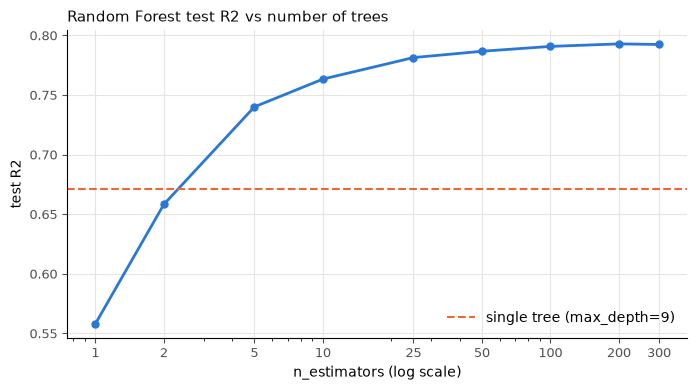

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(n_results.index, n_results["test R2"], color=BLUE, linewidth=2, marker="o", markersize=5)
ax.axhline(r2_score(y_test, tree_9.predict(X_test)), color=ORANGE, linewidth=1.5, linestyle="--", label="single tree (max_depth=9)")
ax.set_xscale("log"); ax.set_xticks(counts); ax.set_xticklabels(counts)
ax.set_xlabel("n_estimators (log scale)"); ax.set_ylabel("test R2")
ax.set_title("Random Forest test R2 vs number of trees", loc="left", fontsize=11, color=INK)
ax.legend(frameon=False, loc="lower right"); style(ax)
plt.show()

**អានលទ្ធផល:**
- Forest ដែលមាន tree **តែមួយ** (R² 0.558) អន់ជាង tree depth 9 ព្រោះវាជ្រៅ (គ្មានដែនកំណត់) ហើយឃើញតែ bootstrap sample។
- ការកើនឡើងលឿនបំផុតនៅ 1 → 10 trees (0.558 → 0.763) ហើយ **រាបស្មើបន្ទាប់ពីប្រហែល 50–100 trees** (0.787 នៅ 50, 0.791 នៅ 100, 0.793 នៅ 200)។ 300 trees (0.7925) មិនល្អជាង 200 ទេ (ភាពខុសគ្នាតូចជាង noise)។
- **Trees ច្រើនជាងមិនដែល overfit ទេ**: ពិន្ទុរាបស្មើ ហើយ trees បន្ថែមគ្រាន់តែចំណាយពេលច្រើនជាង។ ខុសពី `max_depth` ឬ `k` របស់ KNN ដែលត្រូវ tune ប្រយ័ត្ន។

## 5. max_features and min_samples_leaf, chosen by OOB
ជ្រើស hyperparameters ដោយ **OOB R²** (ពី training set តែប៉ុណ្ណោះ) ហើយ **មិនមែនដោយ test set** ដូចក្នុង Lessons 3–4។ ប្រើ 100 trees ដើម្បីឲ្យលឿន។
- `max_features`: សមាមាត្រនៃ features ដែលអាចប្រើបានក្នុង split នីមួយៗ (តិច = trees ខុសគ្នាជាង)
- `min_samples_leaf`: ចំនួន rows អប្បបរមាក្នុង leaf (ធំ = tree រលោងជាង)

In [7]:
rows = []
for mf in [0.33, 0.5, 0.75, 1.0]:
    for msl in [1, 3, 5, 10]:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = RandomForestRegressor(n_estimators=100, max_features=mf, min_samples_leaf=msl, oob_score=True,
                                      random_state=42, n_jobs=-1).fit(X_train, y_train)
        rows.append({"max_features": mf, "min_samples_leaf": msl, "OOB R2": m.oob_score_})
oob = pd.DataFrame(rows)
oob.pivot(index="max_features", columns="min_samples_leaf", values="OOB R2").round(4)

min_samples_leaf,1,3,5,10
max_features,,,,
0.33,0.7807,0.7759,0.7692,0.7546
0.50,0.7861,0.7851,0.7813,0.7664
0.75,0.7822,0.7826,0.7791,0.7689
1.00,0.7781,0.7788,0.7761,0.7657


In [8]:
best = oob.loc[oob["OOB R2"].idxmax()]
best_mf, best_msl = float(best["max_features"]), int(best["min_samples_leaf"])
{"best max_features": best_mf, "best min_samples_leaf": best_msl, "best OOB R2": round(float(best["OOB R2"]), 4)}

{'best max_features': 0.5, 'best min_samples_leaf': 1, 'best OOB R2': 0.7861}

**អានលទ្ធផល:**
- **`max_features = 0.5`** (ប្រើពាក់កណ្តាលនៃ features គ្រប់ split) ល្អបំផុត: OOB R² **0.7861**។ តម្លៃលំនាំដើម `1.0` ទទួលបាន 0.7781 ហើយ `0.33` (តិចពេក) ទទួលបាន 0.7807។ **ការចៃដន្យបន្ថែមជួយបន្តិច** ព្រោះវាធ្វើឲ្យ trees ខុសគ្នាជាង → ការយកមធ្យមបន្ថយ variance ច្រើនជាង។
- **`min_samples_leaf = 1`** ល្អបំផុត (ឬស្ទើរតែល្អបំផុត គម្លាតតិចជាង 0.0005) សម្រាប់ `max_features` ទាំងអស់: leaf ធំជាង (5, 10) ធ្វើឲ្យ OOB R² ធ្លាក់ចុះ (0.7861 → 0.7664 សម្រាប់ `max_features=0.5`)។ ផ្ទុយពី tree តែមួយ, forest មិនត្រូវការកំណត់ដែនកំណត់ tree ទេ ព្រោះការយកមធ្យមកាត់បន្ថយ variance រួចហើយ ហើយ tree ជ្រៅមាន bias ទាប។
- **ភាពខុសគ្នាតូច:** ពិន្ទុទាំង 16 ស្ថិតក្នុងចន្លោះ 0.7546–0.7861 ហើយ 10 ក្នុងចំណោមនោះនៅក្នុង 0.01 នៃកំពូល។ Forest មិនប្រកាន់ hyperparameters ខ្លាំងទេ។

Train forest ចុងក្រោយជាមួយ hyperparameters ទាំងនេះ (300 trees) ហើយវាយតម្លៃ **ម្តង** លើ test set។ ពិនិត្យ residual plot និង predicted vs actual។

In [9]:
forest_tuned = RandomForestRegressor(n_estimators=300, max_features=best_mf, min_samples_leaf=best_msl,
                                     oob_score=True, random_state=42, n_jobs=-1).fit(X_train, y_train)
pd.DataFrame({"Random Forest (default)": evaluate(forest, X_train, X_test),
              "Random Forest (tuned by OOB)": evaluate(forest_tuned, X_train, X_test)}).T.round(3).assign(
    OOB_R2=[round(forest.oob_score_, 3), round(forest_tuned.oob_score_, 3)])

,train MAE,train RMSE,train R2,test MAE,test RMSE,test R2,OOB_R2
Random Forest (default),0.112,0.167,0.970,0.298,0.446,0.792,0.783
Random Forest (tuned by OOB),0.110,0.164,0.972,0.295,0.441,0.797,0.792


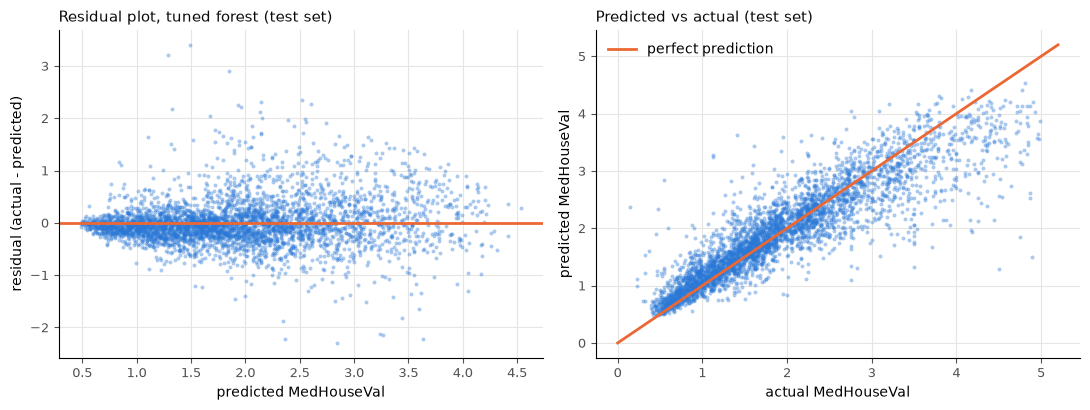

In [10]:
pred_test = forest_tuned.predict(X_test)
resid = y_test - pred_test

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.scatter(pred_test, resid, s=8, color=BLUE, alpha=0.4, linewidth=0)
ax1.axhline(0, color=ORANGE, linewidth=2)
ax1.set_xlabel("predicted MedHouseVal"); ax1.set_ylabel("residual (actual - predicted)")
ax1.set_title("Residual plot, tuned forest (test set)", loc="left", fontsize=11, color=INK); style(ax1)

ax2.scatter(y_test, pred_test, s=8, color=BLUE, alpha=0.4, linewidth=0)
lims = [0, 5.2]
ax2.plot(lims, lims, color=ORANGE, linewidth=2, label="perfect prediction")
ax2.set_xlabel("actual MedHouseVal"); ax2.set_ylabel("predicted MedHouseVal")
ax2.set_title("Predicted vs actual (test set)", loc="left", fontsize=11, color=INK)
ax2.legend(frameon=False); style(ax2)
fig.tight_layout()
plt.show()

**អានលទ្ធផល:** Forest tuned (`max_features=0.5`): test **MAE 0.295, RMSE 0.441, R² 0.797**, OOB R² 0.792 (ជិត test ម្តងទៀត)។ ល្អជាង default បន្តិច (R² 0.792) ដូច OOB បានព្យាករ។
- **Predicted vs actual:** ចំណុចជិតបន្ទាត់ជាងឆ្ងាយ (Lesson 2–4) ហើយគ្មានតម្លៃអវិជ្ជមាន។ សម្រាប់សង្កាត់ថ្លៃបំផុត (actual > 3.5) ចំណុចភាគច្រើននៅក្រោមបន្ទាត់ម្តងទៀត។ Forest នៅទាយទាបពេកសម្រាប់ផ្ទះថ្លៃបំផុត។
- **Residual plot:** ពពកតូចជាងមុន (កំហុសតូចជាង) និងមិនមានរាងកោងទេ ប៉ុន្តែនៅមានរាងចីវលោ: កំហុសកើនឡើងជាមួយតម្លៃទាយ។

## 6. Feature importances: impurity vs permutation
- **Impurity importance** (`feature_importances_`): feature នោះបន្ថយ MSE សរុបបានប៉ុន្មានក្នុង **training**។ លឿន ប៉ុន្តែលម្អៀងទៅរក features ដែលមានតម្លៃច្រើនបែប (`Population`, `AveOccup`)។
- **Permutation importance** (លើ **test set**): កូរតម្លៃរបស់ feature មួយ ហើយមើលថា test R² ធ្លាក់ប៉ុន្មាន។ ធ្លាក់ច្រើន = model ពឹងលើ feature នោះច្រើន។ គ្មានលម្អៀងទៅរក training data។

In [11]:
perm = permutation_importance(forest_tuned, X_test, y_test, n_repeats=5, random_state=42, n_jobs=-1)
importance = pd.DataFrame({
    "impurity (train)": forest_tuned.feature_importances_,
    "permutation (test), R2 drop": perm.importances_mean,
    "permutation std": perm.importances_std,
}, index=feature_names).sort_values("permutation (test), R2 drop", ascending=False)
importance.round(3)

,impurity (train),"permutation (test), R2 drop",permutation std
MedInc,0.397,0.600,0.017
Latitude,0.132,0.455,0.010
Longitude,0.134,0.377,0.009
AveOccup,0.125,0.184,0.009
HouseAge,0.055,0.055,0.003
AveRooms,0.085,0.033,0.001
Population,0.034,0.009,0.001
AveBedrms,0.038,0.006,0.001


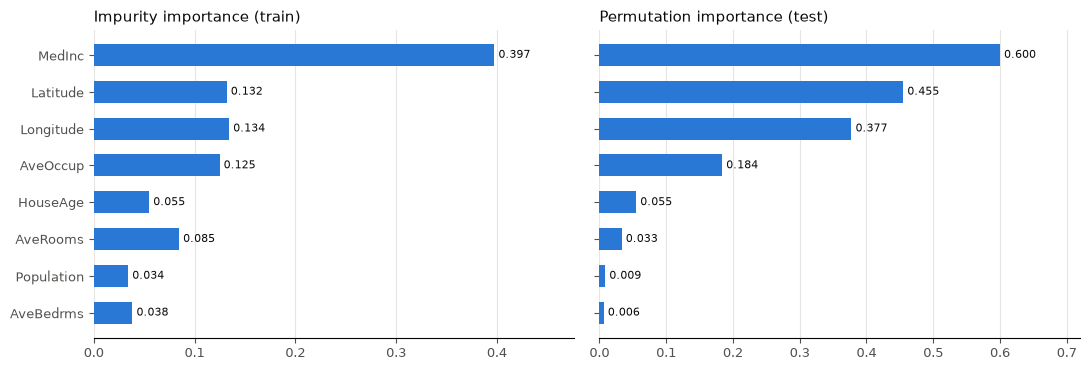

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
order = importance.index[::-1]
for ax, col, title in zip(axes, ["impurity (train)", "permutation (test), R2 drop"],
                          ["Impurity importance (train)", "Permutation importance (test)"]):
    bars = ax.barh(order, importance.loc[order, col], color=BLUE, height=0.6)
    ax.bar_label(bars, fmt="%.3f", padding=3, color=INK, fontsize=8)
    ax.set_title(title, loc="left", fontsize=11, color=INK)
    ax.set_xlim(0, importance[col].max() * 1.2)
    ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.tick_params(colors=MUTED, labelsize=9)
fig.tight_layout()
plt.show()

**អានលទ្ធផល:**
- **`MedInc` ជាប់ចំណាត់ថ្នាក់ទី 1** ក្នុង importance ទាំងពីរ (impurity 0.397; permutation 0.600: ការកូរ `MedInc` ធ្វើឲ្យ test R² ធ្លាក់ 0.60)។ Linear Regression និង tree ក៏យល់ស្របដែរ។
- **ទីតាំង (`Latitude`, `Longitude`) សំខាន់ខ្លាំង:** permutation ធ្លាក់ 0.455 និង 0.377 ដែលបូកគ្នាធំជាង `MedInc` ទៅទៀត។ Forest ប្រើទីតាំងរួមគ្នាជាមួយចំណូល (ការរួមបញ្ចូលដែល Linear Regression មិនអាចចាប់បាន)។
- **Impurity importance លម្អៀង:** វាឲ្យ `AveRooms` 0.085 ដែលខ្ពស់ជាង `HouseAge` (0.055) ប៉ុន្តែ permutation បង្ហាញថា `HouseAge` (0.055) សំខាន់ជាង `AveRooms` (0.033)។ `Population` (0.034) និង `AveBedrms` (0.038) ក៏ត្រូវបាន impurity ប៉ាន់ស្មានខ្ពស់ពេក ទល់នឹង permutation (0.009 និង 0.006)។
  មូលហេតុ: features ដែលមានតម្លៃបន្តច្រើនបែបផ្តល់ឱកាសច្រើនក្នុងការបំបែក ដូច្នេះ impurity លម្អៀងទៅរកពួកវា ហើយវាស់លើ training ដែលរួមបញ្ចូល noise។
- **Permutation importance** វាស់លើ **test set** ដូច្នេះជឿជាក់ជាង។ ចំណាំ: features ដែលទាក់ទងគ្នា (`Latitude`/`Longitude`, `AveRooms`/`AveBedrms`) អាចចែក importance គ្នា។
- Importance **គ្មានសញ្ញា**: វាមិនប្រាប់ថាចំណូលខ្ពស់ជាងបង្កើនតម្លៃទេ (មើល Lesson 2)។

## 7. Comparison with earlier models
Split ដដែល។ Linear Regression និង KNN ប្រើ data ដែល scale (ដូច Lessons 2 និង 3); trees និង forests ប្រើ data គ្មាន scaling។

In [13]:
comparison = pd.DataFrame({
    "Baseline (mean)": evaluate(DummyRegressor(strategy="mean").fit(X_train_s, y_train), X_train_s, X_test_s),
    "Linear Regression": evaluate(LinearRegression().fit(X_train_s, y_train), X_train_s, X_test_s),
    "KNN (k=15)": evaluate(KNeighborsRegressor(n_neighbors=15).fit(X_train_s, y_train), X_train_s, X_test_s),
    "Tree (max_depth=9)": evaluate(tree_9, X_train, X_test),
    "Random Forest (default)": evaluate(forest, X_train, X_test),
    "Random Forest (tuned by OOB)": evaluate(forest_tuned, X_train, X_test),
}).T.round(3)
comparison

,train MAE,train RMSE,train R2,test MAE,test RMSE,test R2
Baseline (mean),0.779,0.971,0.000,0.790,0.979,-0.000
Linear Regression,0.438,0.587,0.634,0.439,0.590,0.636
KNN (k=15),0.354,0.498,0.737,0.380,0.535,0.701
Tree (max_depth=9),0.324,0.462,0.774,0.385,0.561,0.671
Random Forest (default),0.112,0.167,0.970,0.298,0.446,0.792
Random Forest (tuned by OOB),0.110,0.164,0.972,0.295,0.441,0.797


**អានលទ្ធផល:**
- **Random Forest (tuned)** ឈ្នះគ្រប់ models មុនៗ: **R² 0.797, MAE 0.295, RMSE 0.441** ទល់ KNN (0.701 / 0.380 / 0.535), tree (0.671 / 0.385 / 0.561) និង Linear (0.636 / 0.439 / 0.590)។
- MAE ទាបជាង Linear Regression **33%** (0.295 ទល់ 0.439) ហើយទាបជាង KNN ≈ 22%។ ដោយមាន 3,887 test rows ភាពខុសគ្នានេះជា **ពិតប្រាកដ** មិនមែន noise ទេ។
- **Train R² 0.972 ទល់ test 0.797**: ភាពខុសគ្នាធំ ប៉ុន្តែ test score នៅតែល្អបំផុត ហើយ OOB (0.792) បញ្ជាក់ថា test score មិនមែនសំណាងល្អទេ។
- Models ខ្លាំងៗលើ tabular data ជាធម្មតាចាប់យកទំនាក់ទំនងមិនត្រង់ និង interaction ដោយស្វ័យប្រវត្តិ។ Lesson 7 (XGBoost) សាកល្បងវិធីមួយទៀតដើម្បីរួមបញ្ចូល trees: ម្នាក់កែកំហុសរបស់ម្នាក់មុន។

## 8. Predict for the two made-up neighbourhoods
សង្កាត់ដូចគ្នាពី Lessons 2–4។ ការទាយរបស់ forest = មធ្យមនៃ trees។ យើងក៏អាចមើល **ការរាយប៉ាយ** (std) នៃការទាយរបស់ trees នីមួយៗ ជាសញ្ញានៃភាពមិនប្រាកដប្រជា។

In [14]:
new_neighbourhoods = pd.DataFrame([
    {"MedInc": 8.0, "HouseAge": 25, "AveRooms": 6.5, "AveBedrms": 1.0, "Population": 1500,
     "AveOccup": 2.8, "Latitude": 34.05, "Longitude": -118.40},
    {"MedInc": 2.2, "HouseAge": 35, "AveRooms": 4.8, "AveBedrms": 1.1, "Population": 1800,
     "AveOccup": 3.4, "Latitude": 36.75, "Longitude": -119.80},
], index=["high income, Los Angeles coast", "low income, inland Central Valley"])
per_tree = np.array([t.predict(new_neighbourhoods.to_numpy()) for t in forest_tuned.estimators_])   # (300 trees, 2 neighbourhoods)
pd.DataFrame({
    "price (forest, tuned)": forest_tuned.predict(new_neighbourhoods).round(2),
    "std across the 300 trees": per_tree.std(axis=0).round(2),
    "min tree": per_tree.min(axis=0).round(2),
    "max tree": per_tree.max(axis=0).round(2),
    "price (single tree, depth 9)": tree_9.predict(new_neighbourhoods).round(2),
}, index=new_neighbourhoods.index)

,"price (forest, tuned)",std across the 300 trees,min tree,max tree,"price (single tree, depth 9)"
"high income, Los Angeles coast",4.07,0.61,1.72,4.96,4.29
"low income, inland Central Valley",0.59,0.08,0.27,1.10,0.70


**អានលទ្ធផល:** Forest ទាយសង្កាត់ Los Angeles = **4.07** ($407,000) និង Central Valley = **0.59** ($59,000)។ ល្អជាង tree តែមួយ (4.29 និង 0.70) ដែលអាចមិនស្ថិតស្ថេរ។

**ការរាយប៉ាយរបស់ trees** ប្រាប់ពីភាពមិនប្រាកដប្រជា: សម្រាប់សង្កាត់ Central Valley trees ស្ទើរតែយល់ស្របគ្នា (std 0.08, ចន្លោះ 0.27–1.10) ចំណែកសង្កាត់ LA ចំណូលខ្ពស់ trees មិនយល់ស្របគ្នាច្រើន (std 0.61, ចន្លោះ 1.72–4.96)។
នេះសមហេតុផល: សង្កាត់ថ្លៃមានតម្លៃពិតរាយប៉ាយច្រើន (ជាពិសេសបើចំណូលខ្ពស់ត្រូវនឹងទីតាំងខុសគ្នា) ដូច្នេះការទាយមិនប្រាកដប្រជាជាង។ នេះជាប្រយោជន៍បន្ថែមរបស់ forest ដែល tree តែមួយមិនមាន។

## Lesson summary
- **Random Forest** = trees ជ្រៅជាច្រើន ដែលនីមួយៗ train លើ bootstrap sample និងប្រើ features ចៃដន្យ។ **Regression ទាយមធ្យម** នៃ trees ទាំងអស់។
- **Tree តែមួយមិនស្ថិតស្ថេរ**: 5 trees លើ bootstrap ផ្សេងគ្នាបានពិន្ទុ R² 0.603–0.648; មធ្យមនៃ 5 ផ្តល់ 0.723។ ការយកមធ្យមបន្ថយ **variance**។
- **OOB score** ជា validation ឥតគិតថ្លៃ: OOB R² 0.792 ត្រូវនឹង test R² 0.797 ដែលមិនប្រើ test set ក្នុងការជ្រើស hyperparameters។
- **Trees ច្រើនជាងមិន overfit**: ពិន្ទុរាបស្មើបន្ទាប់ពី ~100 trees (0.791) ហើយ trees បន្ថែមគ្រាន់តែចំណាយពេល។
- **`max_features`** (default `1.0` សម្រាប់ regression) ជា hyperparameter ដែលគួរ tune: `0.5` ល្អបំផុត (OOB R² 0.786 ទល់ 0.778)។ `min_samples_leaf` ធំជាងធ្វើឲ្យអន់ជាង។
- **លទ្ធផល: test MAE 0.295, RMSE 0.441, R² 0.797**: ឈ្នះ Linear (0.636), KNN (0.701) និង tree តែមួយ (0.671)។
- **Impurity importance លម្អៀង** (feature មានតម្លៃច្រើនបែប) ហើយវាស់លើ training; **permutation importance** លើ test ជឿជាក់ជាង: `MedInc` 0.60, `Latitude` 0.455, `Longitude` 0.377។ Importance គ្មានសញ្ញា។
- Forest នៅតែទាយទាបពេកសម្រាប់សង្កាត់ថ្លៃបំផុត ហើយ train R² (0.972) ខ្ពស់ជាង test (0.797) ច្រើន។
- Std នៃការទាយរបស់ trees ប្រាប់ពីភាពមិនប្រាកដប្រជាសម្រាប់សង្កាត់នីមួយៗ។
- ត្រង់នេះ **គ្មានផ្នែក "Duplicates across train and test"** ព្រោះ notebook 01 បានបង្ហាញថាគ្មាន rows ស្ទួន។
- Lesson 6 (SVM) សាកល្បង model ដែលប្រើ **kernel** ដើម្បីចាប់យកទំនាក់ទំនងកោង ហើយ Lesson 7 (XGBoost) រួមបញ្ចូល trees តាមរបៀប boosting។